# Ordinary and neural-guided GFMC: matched 12-spin benchmark

**Pure GFMC** here means ordinary propagation with a constant guide
$\psi_T(s)=1$. **Guided GFMC** uses the same frozen shared seed501 transformer
$\psi_T(s)=\sqrt{p_\theta(s)}$. Both use the same continuous-time projector,
branching cadence, walker counts, times, disorder samples, and seed list.
Initial samples follow the corresponding trial probability. Exact ground states
provide evaluation targets only. No optimizer is constructed.

Energy is a mixed estimator. Connected susceptibility uses four physical
replicas and forward walking in **both** methods. Thus “pure” in the title
describes the guide; pure diagonal estimation is common to both methods.
All forward cycles are retained, including those with poor ancestry.
Error bars are standard errors across four independent populations.

The network uses a complete 12-spin lookup of its frozen amplitudes.
Recorded cost includes propagation and initial sampling, and excludes lookup
construction, cache loading, and direct neural inference. Efficiency ratios
here assess the stochastic algorithms with lookup rates. Larger-system
efficiency needs direct-inference costs and its own convergence checks.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
ROOT=Path('/Users/tianyiyan/Dropbox/spin-glasses/data/kagome/transformer_af_pure_vs_guided_preview_v1')
summary=json.loads((ROOT/'summary.json').read_text())
manifest=summary['manifest']
rows=summary['rows']
assert not manifest['reserved_test_ids_inspected']
display(Markdown(f"Completed populations: **{summary['completed_populations']}/{summary['expected_populations']}**; complete=**{summary['completed']}**. Completed groups: **{len(rows)}**."))
display(manifest['design'])
if (ROOT/'status.json').exists(): display(json.loads((ROOT/'status.json').read_text()))
display(Markdown('Frozen guide SHA-256: `'+manifest['checkpoint_sha256']+'`'))


Completed populations: **16/16**; complete=**True**. Completed groups: **4**.

{'contexts': [{'gamma': 0.5, 'h': 0.3, 'K': 1.0},
  {'gamma': 0.5, 'h': 0.3, 'K': 2.0}],
 'sample_ids': [10000],
 'walkers': [512],
 'forward_Ktau': [2.0],
 'branch_Ktau': 0.1,
 'equilibration_Ktau': 8.0,
 'measurement_Ktau': 2.0,
 'cycles': 6,
 'seeds': [98200, 98201, 98202, 98203],
 'guides': ['constant', 'network']}

{'state': 'completed',
 'pid': 55340,
 'updated_unix': 1793058191.836614,
 'completed_populations': 16,
 'expected_populations': 16}

Frozen guide SHA-256: `5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544`

## Initial guide quality

Fidelity and local-energy variance are evaluated by enumeration. They describe
the initial trial state, before stochastic projection. Poor trial fidelity can
coexist with useful importance sampling; the projected observables below decide
whether the guide helps in practice.


In [2]:
table=['| Γ | h | K | Disorder | Guide | Initial fidelity | Initial Var(E local) |','|---|---|---|---|---|---:|---:|']
seen=set()
for r in rows:
    context=(r['gamma'],r['h'],r['K'],r['sample_id'],r['guide'])
    if context in seen: continue
    seen.add(context)
    table.append(f"| {r['gamma']:g} | {r['h']:g} | {r['K']:g} | {r['sample_id']} | {r['guide']} | {r['initial_fidelity']:.6f} | {r['initial_local_energy_variance']:.6f} |")
display(Markdown('\n'.join(table)))


| Γ | h | K | Disorder | Guide | Initial fidelity | Initial Var(E local) |
|---|---|---|---|---|---:|---:|
| 0.5 | 0.3 | 1 | 10000 | constant | 0.031114 | 28.335884 |
| 0.5 | 0.3 | 1 | 10000 | network | 0.561591 | 0.457691 |
| 0.5 | 0.3 | 2 | 10000 | constant | 0.005645 | 110.103535 |
| 0.5 | 0.3 | 2 | 10000 | network | 0.039177 | 2.372802 |

## Matched stochastic results

Energy errors are per spin; susceptibility is the connected spin-glass
susceptibility. Each row combines four independent populations. The smallest
ancestry ESS and largest lineage include every forward cycle. Agreement of
energy alone does not establish correlation convergence.


In [3]:
table=['| Γ | h | K | Disorder | Guide | W | Kτ forward | (E−E₀)/N ± SE | χ ± SE | Exact χ | Min ancestry ESS | Largest lineage | Seconds |','|---|---|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|']
for r in rows:
    e=r['observables']['energy']; c=r['observables']['chi_connected']
    table.append(f"| {r['gamma']:g} | {r['h']:g} | {r['K']:g} | {r['sample_id']} | {r['guide']} | {r['walkers']} | {r['forward_Ktau']:g} | {e['bias']/12:.6f} ± {e['se']/12:.6f} | {c['mean']:.5f} ± {c['se']:.5f} | {c['exact']:.5f} | {r['min_descendant_ess']:.2f} | {r['max_largest_lineage']:.3f} | {r['seconds']:.2f} |")
display(Markdown('\n'.join(table)))


| Γ | h | K | Disorder | Guide | W | Kτ forward | (E−E₀)/N ± SE | χ ± SE | Exact χ | Min ancestry ESS | Largest lineage | Seconds |
|---|---|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.5 | 0.3 | 1 | 10000 | constant | 512 | 2 | 0.033446 ± 0.011523 | 1.48489 ± 0.41526 | 0.11846 | 1.13 | 0.939 | 2.28 |
| 0.5 | 0.3 | 1 | 10000 | network | 512 | 2 | 0.000932 ± 0.000520 | 0.29476 ± 0.00953 | 0.11846 | 97.23 | 0.055 | 2.05 |
| 0.5 | 0.3 | 2 | 10000 | constant | 512 | 2 | 0.089439 ± 0.005344 | 2.18275 ± 0.82184 | 0.03613 | 1.27 | 0.883 | 1.62 |
| 0.5 | 0.3 | 2 | 10000 | network | 512 | 2 | 0.036913 ± 0.004924 | 1.81323 ± 0.65644 | 0.03613 | 3.75 | 0.506 | 1.48 |

## Population and forward-time dependence

Biases are plotted against exact ground-state targets. Lines connect forward
times at fixed population and method. Error bars represent statistical
uncertainty; projection and population bias require stability as settings grow.


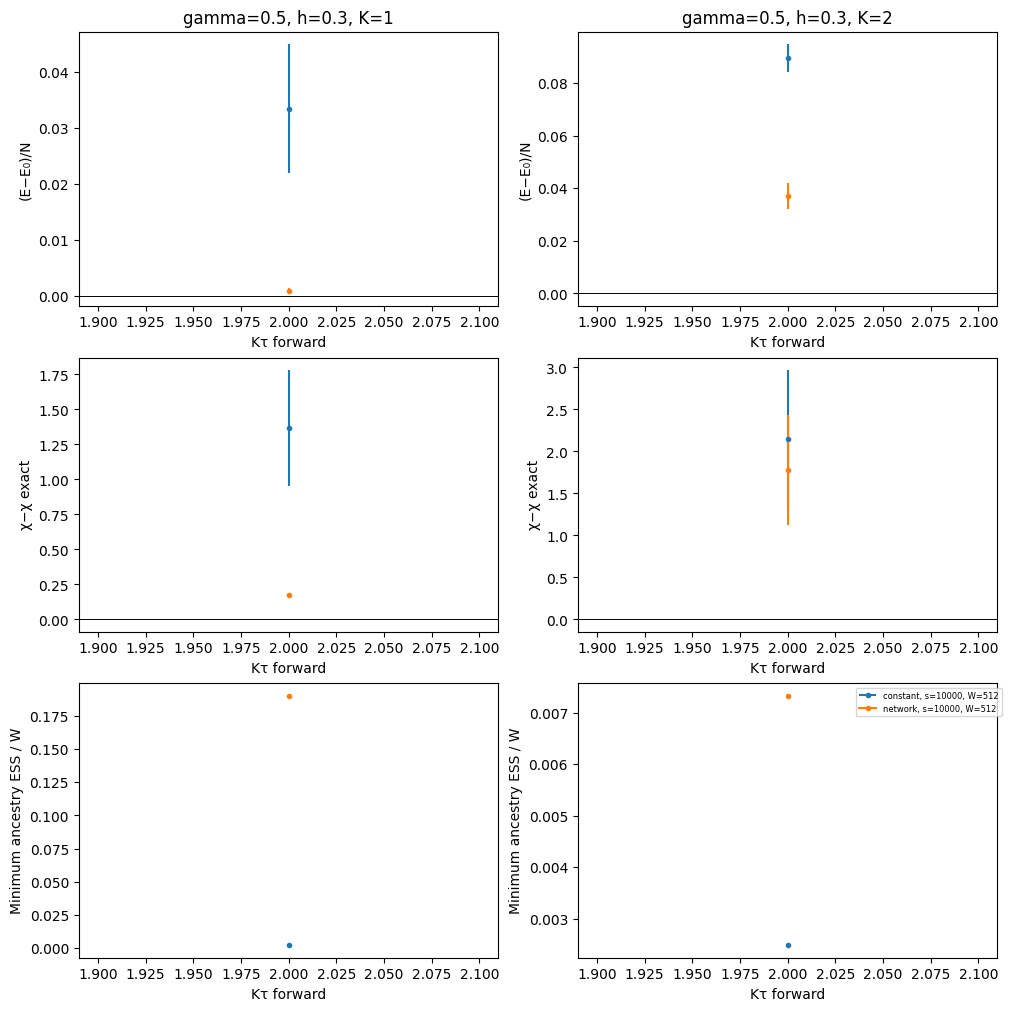

In [4]:
contexts=manifest['design']['contexts']
fig,axes=plt.subplots(3,len(contexts),figsize=(5*len(contexts),10),squeeze=False,constrained_layout=True)
for col,context in enumerate(contexts):
    for sid in manifest['design']['sample_ids']:
        for W in manifest['design']['walkers']:
            for kind,style in [('constant','--'),('network','-')]:
                group=sorted([r for r in rows if all(r[k]==v for k,v in context.items()) and r['sample_id']==sid and r['walkers']==W and r['guide']==kind],key=lambda r:r['forward_Ktau'])
                if not group: continue
                x=[r['forward_Ktau'] for r in group]
                label=f'{kind}, s={sid}, W={W}'
                for ax,metric,factor in [(axes[0,col],'energy',12),(axes[1,col],'chi_connected',1)]:
                    ax.errorbar(x,[r['observables'][metric]['bias']/factor for r in group],yerr=[r['observables'][metric]['se']/factor for r in group],marker='.',linestyle=style,label=label)
                axes[2,col].plot(x,[r['min_descendant_ess']/W for r in group],marker='.',linestyle=style,label=label)
    for row,ylabel in enumerate(['(E−E₀)/N','χ−χ exact','Minimum ancestry ESS / W']):
        axes[row,col].set(xlabel='Kτ forward',ylabel=ylabel)
        if row<2: axes[row,col].axhline(0,color='k',lw=.7)
    axes[0,col].set_title(', '.join(f'{k}={v:g}' for k,v in context.items()))
axes[-1,-1].legend(fontsize=6,bbox_to_anchor=(1.02,1))
fig.savefig(ROOT/'pure_vs_guided_convergence.png',dpi=160)
plt.show()


## Measured uncertainty and lookup cost

The ratio below is `(constant SE² × constant seconds) / (network SE² × network
seconds)` for matched settings. Values above one favor the network in variance
per measured cost. Four populations give a noisy variance estimate. Bias must
be assessed separately in the table above, and these lookup measurements
exclude direct transformer inference.


In [5]:
lookup={(r['gamma'],r['h'],r['K'],r['sample_id'],r['walkers'],r['forward_Ktau'],r['guide']):r for r in rows}
table=['| Γ | h | K | Disorder | W | Kτ forward | Constant/network seconds | Energy efficiency ratio | χ efficiency ratio |','|---|---|---|---|---:|---:|---:|---:|---:|']
for r in rows:
    if r['guide']!='constant': continue
    k=(r['gamma'],r['h'],r['K'],r['sample_id'],r['walkers'],r['forward_Ktau'],'network')
    n=lookup.get(k)
    if n is None: continue
    ratios={}
    for metric in ['energy','chi_connected']:
        denom=n['observables'][metric]['se']**2*n['seconds']
        ratios[metric]=r['observables'][metric]['se']**2*r['seconds']/denom if denom else float('nan')
    table.append(f"| {r['gamma']:g} | {r['h']:g} | {r['K']:g} | {r['sample_id']} | {r['walkers']} | {r['forward_Ktau']:g} | {r['seconds']/n['seconds']:.3f} | {ratios['energy']:.3f} | {ratios['chi_connected']:.3f} |")
display(Markdown('\n'.join(table)))


| Γ | h | K | Disorder | W | Kτ forward | Constant/network seconds | Energy efficiency ratio | χ efficiency ratio |
|---|---|---|---|---:|---:|---:|---:|---:|
| 0.5 | 0.3 | 1 | 10000 | 512 | 2 | 1.112 | 545.716 | 2110.810 |
| 0.5 | 0.3 | 2 | 10000 | 512 | 2 | 1.098 | 1.293 | 1.720 |

## Deterministic projection references

These curves project the constant and network trial amplitudes exactly in
the 12-spin Hilbert space. Fidelity and full connected-matrix errors measure
remaining projection error without walker noise or finite-population bias.
The pure projected state differs from a finite-forward-time stochastic
estimator; these curves serve as projection diagnostics.


| Γ | h | K | Disorder | Guide | Fidelity at Kτ16 | Fidelity at Kτ64 | C RMS error at Kτ64 |
|---|---|---|---|---|---:|---:|---:|
| 0.5 | 0.3 | 1 | 10000 | constant | 0.999945 | 1.000000 | 0.000000 |
| 0.5 | 0.3 | 1 | 10000 | network | 0.999961 | 1.000000 | 0.000000 |
| 0.5 | 0.3 | 2 | 10000 | constant | 0.999648 | 1.000000 | 0.000000 |
| 0.5 | 0.3 | 2 | 10000 | network | 0.998360 | 1.000000 | 0.000000 |

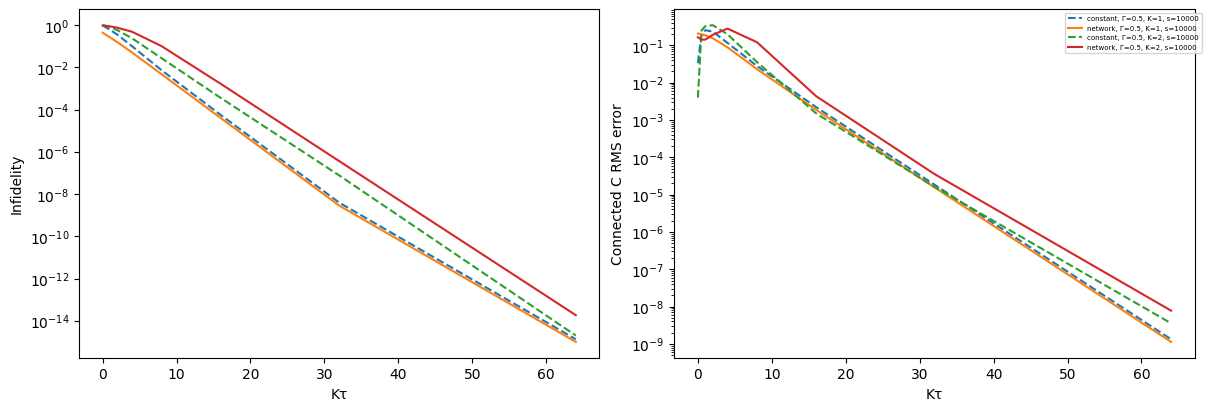

### Exact finite-forward-time targets

For a tag at time $t$ followed for $f$, the infinite-population ancestor probability is proportional to $\phi_t(s)\phi_f(s)$, where $\phi_t=e^{-tH}\psi_T$. The table averages the same cycle times as the stochastic run. This separates forward-time bias from finite-population error.

| Γ | K | Disorder | Guide | W | Kτ forward | Stochastic χ ± SE | Infinite-population finite-time χ | Exact ground-state χ |
|---|---|---|---|---:|---:|---:|---:|---:|
| 0.5 | 1 | 10000 | constant | 512 | 2 | 1.48489 ± 0.41526 | 0.36438 | 0.11846 |
| 0.5 | 1 | 10000 | network | 512 | 2 | 0.29476 ± 0.00953 | 0.27301 | 0.11846 |
| 0.5 | 2 | 10000 | constant | 512 | 2 | 2.18275 ± 0.82184 | 0.12347 | 0.03613 |
| 0.5 | 2 | 10000 | network | 512 | 2 | 1.81323 ± 0.65644 | 0.37923 | 0.03613 |

In [6]:
p=ROOT/'projection_reference.json'
if p.exists():
    references=json.loads(p.read_text())
    assert references['checkpoint_sha256']==manifest['checkpoint_sha256']
    assert references['input_sha256']==manifest['input_sha256']
    fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    table=['| Γ | h | K | Disorder | Guide | Fidelity at Kτ16 | Fidelity at Kτ64 | C RMS error at Kτ64 |','|---|---|---|---|---|---:|---:|---:|']
    for r in references['rows']:
        t=r['trajectory']; end=t[-1]; mid=next(v for v in t if v['Ktau']==16)
        table.append(f"| {r['gamma']:g} | {r['h']:g} | {r['K']:g} | {r['sample_id']} | {r['guide']} | {mid['fidelity']:.6f} | {end['fidelity']:.6f} | {end['connected_correlation_rms_error']:.6f} |")
        label=f"{r['guide']}, Γ={r['gamma']:g}, K={r['K']:g}, s={r['sample_id']}"
        style='--' if r['guide']=='constant' else '-'
        axes[0].semilogy([v['Ktau'] for v in t],[max(1-v['fidelity'],1e-15) for v in t],style,label=label)
        axes[1].semilogy([v['Ktau'] for v in t],[max(v['connected_correlation_rms_error'],1e-15) for v in t],style,label=label)
    display(Markdown('\n'.join(table)))
    axes[0].set(xlabel='Kτ',ylabel='Infidelity'); axes[1].set(xlabel='Kτ',ylabel='Connected C RMS error')
    axes[1].legend(fontsize=5,bbox_to_anchor=(1.02,1))
    fig.savefig(ROOT/'pure_vs_guided_exact_projection.png',dpi=160)
    plt.show()
    finite=references.get('finite_forward_rows',[])
    finite_lookup={(r['gamma'],r['h'],r['K'],r['sample_id'],r['guide'],r['forward_Ktau']):r for r in finite}
    if finite:
        display(Markdown('### Exact finite-forward-time targets\n\nFor a tag at time $t$ followed for $f$, the infinite-population ancestor probability is proportional to $\phi_t(s)\phi_f(s)$, where $\phi_t=e^{-tH}\psi_T$. The table averages the same cycle times as the stochastic run. This separates forward-time bias from finite-population error.'))
        table=['| Γ | K | Disorder | Guide | W | Kτ forward | Stochastic χ ± SE | Infinite-population finite-time χ | Exact ground-state χ |','|---|---|---|---|---:|---:|---:|---:|---:|']
        for r in rows:
            k=(r['gamma'],r['h'],r['K'],r['sample_id'],r['guide'],r['forward_Ktau'])
            target=finite_lookup.get(k)
            if target is None: continue
            c=r['observables']['chi_connected']
            table.append(f"| {r['gamma']:g} | {r['K']:g} | {r['sample_id']} | {r['guide']} | {r['walkers']} | {r['forward_Ktau']:g} | {c['mean']:.5f} ± {c['se']:.5f} | {target['chi_connected']:.5f} | {c['exact']:.5f} |")
        display(Markdown('\n'.join(table)))
else:
    display(Markdown('Deterministic projection references pending.'))


## Reading the benchmark

Compare methods within each fixed Hamiltonian and setting. Both should approach
the same exact result as projection, forward time, and population grow. A
useful guide reduces uncertainty or required population at comparable bias.
Ancestry collapse, disagreement between populations, and time dependence all
remain visible. This first comparison does not establish convergence at larger
sizes or across disorder, and does not determine a phase boundary.
